# PCA and LSI

**Seong Cho** · ACME Volume 3

**Lab objective:** implement principal component analysis with the SVD, use it to visualize the iris dataset, and apply latent semantic indexing to find the most and least similar presidential addresses.

<sub>Lab specification from the *Volume 3* lab materials of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem descriptions are quoted from the lab's template. Solutions are my own.</sub>

The spec's full problem statements weren't kept with my files; each problem quotes the description from the lab's template.

In [1]:
import os
import string
import numpy as np
from math import log
from scipy import sparse
from sklearn import datasets
from scipy import linalg as la
from collections import Counter
from matplotlib import pyplot as plt
from scipy.sparse import linalg as spla

## The `PCA` class

My file has no template description for this class.

In [2]:
class PCA:
    def __init__(self, X, y=None, s=None, sparse=False, center=True):
        self.X = X - X.mean(axis=0) if center else X
        self.y = y
        if s == None:
            n, d = X.shape
            s = d
        if not sparse:
            U, sig, Vh = la.svd(self.X, full_matrices=False)
            self.sig = sig[:s]**2
            self.Vh = Vh[:s]
        else:
            _, sig, Vh = spla.svds(self.X, k=s, return_singular_vectors="vh")
            self.sig = sig**2
            self.Vh = Vh
        self.a = self.transform(self.X)
        self.proj_X = self.project(self.X)
    
    def transform(self, x):
        return self.Vh@x.T
    
    def project(self, x):
        return self.Vh.T@self.a

A check on the iris data against scikit-learn's `PCA`: the squared singular values, the principal directions and the scores agree up to the sign of each component, and the sparse (`svds`) path gives the same squared singular values, in ascending order.

In [3]:
from sklearn.decomposition import PCA as SKPCA

iris = datasets.load_iris()
pca = PCA(iris.data, y=iris.target, s=2)
sk = SKPCA(n_components=2).fit(iris.data)
print("sig:", pca.sig)
print("Vh:\n", pca.Vh)
print("a:", pca.a.shape, " proj_X:", pca.proj_X.shape)

signs = np.sign(np.sum(pca.Vh * sk.components_, axis=1))
assert np.allclose(pca.sig, sk.singular_values_**2)
assert np.allclose(pca.Vh, signs[:, None] * sk.components_)
assert np.allclose(pca.a.T, sk.transform(iris.data) * signs)
assert np.allclose(pca.proj_X.T, sk.inverse_transform(sk.transform(iris.data)) - iris.data.mean(axis=0))

np.random.seed(0)
pca_sp = PCA(iris.data, s=2, sparse=True)
print("sparse sig:", pca_sp.sig)
assert np.allclose(np.sort(pca_sp.sig), np.sort(pca.sig))

sig: [630.0080142   36.15794144]
Vh:
 [[ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
 [-0.65658877 -0.73016143  0.17337266  0.07548102]]
a: (2, 150)  proj_X: (4, 150)
sparse sig: [ 36.15794144 630.0080142 ]


## Problem 1: PCA on the iris dataset

From the lab's template:

> Recreates the plot shown in Figure 1.4 by performing PCA on the iris dataset, keeping the first two principal components.

In [4]:
def prob1():
    """Recreates the plot shown 
    in Figure 1.4 by performing PCA on the iris dataset, 
    keeping the first two principal components."""
    
    iris = datasets.load_iris()
    iris = datasets.load_iris()
    X = iris['data']
    y = iris['target']
    pca2_iris = PCA(X, y=y, s=2)
    A = np.vstack([pca2_iris.a, pca2_iris.y])
    setosa = A.T[A[2] == 0][:, :2]
    versicolor = A.T[A[2] == 1][:, :2]
    virginica = A.T[A[2] == 2][:, :2]

    plt.scatter(setosa[:, 0], setosa[:, 1], label="setosa", alpha=0.5)
    plt.scatter(versicolor[:, 0], versicolor[:, 1], label="versicolor", alpha=0.5)
    plt.scatter(virginica[:, 0], virginica[:, 1], label="virginica", alpha=0.5)
    plt.legend()
    plt.show()

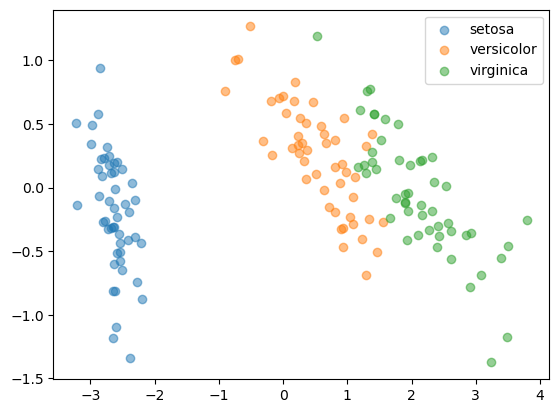

In [5]:
prob1()

## Problem 2: LSI on the word count matrix

From the lab's template:

> Uses LSI, applied to the word count matrix X, with the first 7 principal components to find the most similar and least similar speeches
>
> **Parameters:** speech str: Path to speech eg: `"./Addresses/1984-Reagan.txt"`
>
> **Returns:** tuple of str: (Most similar speech, least similar speech)

In [6]:
def prob2(speech="./Addresses/1984-Reagan.txt"):
    """
    Uses LSI, applied to the word count matrix X, with the first 7 principal
    components to find the most similar and least similar speeches 
    
    Parameters:
        speech str: Path to speech eg: "./Addresses/1984-Reagan.txt"
    
    Returns:
        tuple of str: (Most similar speech, least similar speech) 
    """
    
    # Get list of filepaths to each text file in the folder.
    folder = "./Addresses/"
    paths = [folder+p for p in os.listdir(folder) if p.endswith(".txt")]
    
    # Helper function to get list of words in a string.
    def extractWords(text):
        ignore = string.punctuation + string.digits
        cleaned = "".join([t for t in text.strip() if t not in ignore])
        return cleaned.lower().split()
    
    # Initialize vocab set, then read each file and add to the vocab set.
    vocab = set()
    for p in paths:
        with open(p, 'r') as infile:
            for line in infile:
                vocab.update(extractWords(line))
                
                
    # load stopwords
    with open("stopwords.txt", 'r') as f:
        stops = set([w.strip().lower() for w in f.readlines()])
    
    # remove stopwords from vocabulary, create ordering
    vocab = {w:i for i, w in enumerate(vocab.difference(stops))}
    
    
    counts = []      # holds the entries of X
    doc_index = []   # holds the row index of X
    word_index = []  # holds the column index of X

    # Iterate through the documents.
    for doc, p in enumerate(paths):
        with open(p, 'r') as f:
            # Create the word counter.
            ctr = Counter()
            for line in f:
                ctr.update(extractWords(line))
            # Iterate through the word counter, store counts.
            for word, count in ctr.items():
                if word in vocab:
                    word_index.append(vocab[word])
                    counts.append(count)
                    doc_index.append(doc)
    
    # Create sparse matrix holding these word counts.
    # Changed: dtype=float instead of np.float, which NumPy 1.24 removed.
    X = sparse.csr_matrix((counts, [doc_index, word_index]),
                           shape=(len(paths), len(vocab)), dtype=float)
    
    pca_speech = PCA(X, s=7, sparse=True, center=False)
    speech_idx = paths.index(speech)
    X_hat = pca_speech.a.T
    xj = X_hat[speech_idx]
    similarities = []
    for i,x in enumerate(X_hat):
        if i != speech_idx:
            similarity = np.dot(xj, x) / (la.norm(xj)*la.norm(x))
            similarities.append(similarity)
    del paths[speech_idx]
    most = paths[np.argmax(similarities)]
    least = paths[np.argmin(similarities)]
    most = most.split('/')[-1].split('.')[0]
    least = least.split('/')[-1].split('.')[0]
    return most, least

`svds` starts from a random vector, so the demo seeds NumPy's generator.

In [7]:
np.random.seed(0)
print(len([p for p in os.listdir("./Addresses/") if p.endswith(".txt")]), "speeches")
for speech in ["./Addresses/1984-Reagan.txt", "./Addresses/1993-Clinton.txt", "./Addresses/1945-Truman.txt"]:
    print(speech, prob2(speech))

66 speeches
./Addresses/1984-Reagan.txt ('1988-Reagan', '1946-Truman')


./Addresses/1993-Clinton.txt ('1992-Bush', '2002-GWBush')
./Addresses/1945-Truman.txt ('1980-Carter', '1981-Reagan')


An independent check for every speech: the same word counts built with scikit-learn's `CountVectorizer` (same cleaning and stop words), the first 7 components from `TruncatedSVD`, and `cosine_similarity`.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

names = sorted(p[:-4] for p in os.listdir("./Addresses/") if p.endswith(".txt"))
docs = [open(f"./Addresses/{n}.txt").read() for n in names]
stops_ref = set(open("stopwords.txt").read().lower().split())
table = str.maketrans("", "", string.punctuation + string.digits)
cv = CountVectorizer(analyzer=lambda doc: [w for w in doc.translate(table).lower().split()
                                           if w not in stops_ref])
X_ref = cv.fit_transform(docs).toarray().astype(float)
print("word count matrix:", X_ref.shape)

def lsi_ref(M):
    Z = TruncatedSVD(n_components=7, algorithm="arpack", random_state=0).fit_transform(M)
    S = cosine_similarity(Z)
    np.fill_diagonal(S, np.nan)
    return {n: (names[np.nanargmax(S[i])], names[np.nanargmin(S[i])]) for i, n in enumerate(names)}

ref2 = lsi_ref(X_ref)
np.random.seed(0)
for n in names:
    assert prob2(f"./Addresses/{n}.txt") == ref2[n], n
print("prob2 matches the reference for all", len(names), "speeches.")

word count matrix: (66, 14114)


prob2 matches the reference for all 66 speeches.


## Problem 3: LSI on the globally weighted word count matrix

From the lab's template:

> Uses LSI, applied to the globally weighted word count matrix A, with the first 7 principal components to find the most similar and least similar speeches
>
> **Parameters:** speech str: Path to speech eg: `"./Addresses/1984-Reagan.txt"`
>
> **Returns:** tuple of str: (Most similar speech, least similar speech)

In [9]:
def prob3(speech="./Addresses/1984-Reagan.txt"):
    """
    Uses LSI, applied to the globally weighted word count matrix A, with the 
    first 7 principal components to find the most similar and least similar speeches 
    
    Parameters:
        speech str: Path to speech eg: "./Addresses/1984-Reagan.txt"
    
    Returns:
        tuple of str: (Most similar speech, least similar speech) 
    """
    
    # Get list of filepaths to each text file in the folder.
    folder = "./Addresses/"
    paths = [folder+p for p in os.listdir(folder) if p.endswith(".txt")]
    
    # Helper function to get list of words in a string.
    def extractWords(text):
        ignore = string.punctuation + string.digits
        cleaned = "".join([t for t in text.strip() if t not in ignore])
        return cleaned.lower().split()
    
    # Initialize vocab set, then read each file and add to the vocab set.
    vocab = set()
    for p in paths:
        with open(p, 'r') as infile:
            for line in infile:
                vocab.update(extractWords(line))
                
                
    # load stopwords
    with open("stopwords.txt", 'r') as f:
        stops = set([w.strip().lower() for w in f.readlines()])
    
    # remove stopwords from vocabulary, create ordering
    vocab = {w:i for i, w in enumerate(vocab.difference(stops))}
    
    t = np.zeros(len(vocab))
    counts = []
    doc_index = []
    word_index = []
    
    # get doc-term counts and global term counts
    for doc, path in enumerate(paths):
        with open(path, 'r') as f:
            # create the word counter
            ctr = Counter()
            for line in f:
                words = extractWords(line)
                ctr.update(words)
            # iterate through the word counter, store counts
            for word, count in ctr.items():
                if word in vocab:
                    word_ind = vocab[word]
                    word_index.append(word_ind)
                    counts.append(count)
                    doc_index.append(doc)
                    t[word_ind] += count
    
    # Get global weights.
    g = np.ones(len(vocab))
    logM = log(len(paths))
    for count, word in zip(counts, word_index):
        p = count/float(t[word])
        g[word] += p*log(p+1)/logM
    
    # Get globally weighted counts.
    gwcounts = []
    for count, word in zip(counts, word_index):
        gwcounts.append(g[word]*log(count+1))
    
    # Create sparse matrix holding these globally weighted word counts
    # Changed: dtype=float instead of np.float, which NumPy 1.24 removed.
    A = sparse.csr_matrix((gwcounts, [doc_index,word_index]),
                          shape=(len(paths), len(vocab)), dtype=float)
    
    pca_speech = PCA(A, s=7, sparse=True, center=False)
    speech_idx = paths.index(speech)
    X_hat = pca_speech.a.T
    xj = X_hat[speech_idx]
    similarities = []
    for i,x in enumerate(X_hat):
        if i != speech_idx:
            similarity = np.dot(xj, x) / (la.norm(xj)*la.norm(x))
            similarities.append(similarity)
    del paths[speech_idx]
    most = paths[np.argmax(similarities)]
    least = paths[np.argmin(similarities)]
    most = most.split('/')[-1].split('.')[0]
    least = least.split('/')[-1].split('.')[0]
    return most, least

In [10]:
np.random.seed(0)
for speech in ["./Addresses/1984-Reagan.txt", "./Addresses/1993-Clinton.txt", "./Addresses/1945-Truman.txt"]:
    print(speech, prob3(speech))

./Addresses/1984-Reagan.txt ('1985-Reagan', '1946-Truman')


./Addresses/1993-Clinton.txt ('1995-Clinton', '1946-Truman')


./Addresses/1945-Truman.txt ('1963-Johnson', '1946-Truman')


The same independent check, with the global weights applied to the reference counts the way `prob3()` computes them.

In [11]:
P = X_ref / X_ref.sum(axis=0)
g = 1 + (P * np.log(P + 1)).sum(axis=0) / np.log(len(names))
A_ref = np.log(X_ref + 1) * g

ref3 = lsi_ref(A_ref)
np.random.seed(0)
for n in names:
    assert prob3(f"./Addresses/{n}.txt") == ref3[n], n
print("prob3 matches the reference for all", len(names), "speeches.")

prob3 matches the reference for all 66 speeches.
